In [54]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# Demonstrator 3 - Diffusive operator combined with a dispersive scheme

## Aim of Tutorial

The aim of this tutorial is to dive into the interest of combining a diffusive operator with a dispersive scheme. FCT and UBS methods are examples of schemes where the numerical expression of the methods contains a dispersive term and a diffusive term. Here we choose to deliberately add a diffusive operator to a solely dispersive scheme (CEN) on the saltblock experience to attest of the benefits of having both properties.

To better understand this demonstrator you should follow Demonstrator 1 beforehand.

## Running the simulations


To run the simulation we need change ```ln_traadv_cen``` from ```.false.``` to ```.true.``` and ```nn_cen_h``` and ```nn_cen_v``` from ```4``` to ```2``` in the namelist.

__To make the recquired changes you can either modify the files yourself by follwing the instructions starting 2 cells below or you can execute the cell below__

In [55]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_saltblock_lap_cen2_all_grid.nc
rm CANAL_saltblock_blp_cen2_all_grid.nc
rm CANAL_saltblock_lap_cen4_all_grid.nc
rm CANAL_saltblock_blp_cen4_all_grid.nc
rm CANAL_saltblock_traldfOFF_cen2_all_grid.nc

chmod -R a+x /"$DIR"/demo3_cfg/

sh /"$DIR"/demo3_cfg/diffusion_cfg.sh "$DIR"
sh /"$DIR"/demo3_cfg/lap_cfg.sh "$DIR"; sh /"$DIR"/demo3_cfg/blp_cfg.sh "$DIR"; 
sh /"$DIR"/demo3_cfg/traldfOFF_cfg.sh "$DIR"


rm: impossible de supprimer 'CANAL_saltblock_traldfOFF_cen2_all_grid.nc': No such file or directory
+ set -u
+ '[' 1 -lt 1 ']'
+ DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
+ SRC=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg
+ '[' '!' -f /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg ']'
+ sed -i.bak -e 's/rn_domszx.*=.*\!/rn_domszx      =       1000.    !/' -e 's/rn_domszy.*=.*\!/rn_domszy      =       1000.   !/' -e 's/rn_domszz.*=.*\!/rn_domszz      =       1000.  !/' -e 's/rn_dx.*=.*\!/rn_dx      =       20.     !/' -e 's/rn_dy.*=.*\!/rn_dy      =       20.  !/' -e 's/rn_dz.*=.*\!/rn_dz      =       1000.  !/' -e 's/rn_0xratio.*=.*\!/rn_0xratio    =       0.5  !/' -e 's/rn_0yratio.*=.*\!/rn_0yratio    =       0.5  !/' -e 's/nn_fcase.*=.*\!/nn_fcase        =       0  !/' -e 's/rn_ppgphi0.*=.*\!/rn_ppgphi0    =       38.5  !/' -e 's/rn_u10.*=.*\!/rn_u10    =       0.  !/' -e 's/rn_uzonal.

19,29c19,29
<    rn_domszx      =       1000.    !  x horizontal size         [km]
<    rn_domszy      =       1000.   !  y horizontal size         [km]
<    rn_domszz      =       1000.  !  z vertical size            [m]
<    rn_dx      =       20.     !  x horizontal resolution   [km]
<    rn_dy      =       20.  !  y horizontal resolution   [km]
<    rn_dz      =       1000.  !  z vertical resolution      [m]
<    rn_0xratio    =       0.5  !  x-domain ratio of the 0
<    rn_0yratio    =       0.5  !  y-domain ratio of the 0
<    nn_fcase        =       0  !  F computation (0:f0, 1:Beta, 2:real)
<    rn_ppgphi0    =       38.5  !  Reference latitude      [degrees]
<    rn_u10    =       0.  !  10m wind speed              [m/s]
---
>    rn_domszx	=	864.	!  x horizontal size         [km]
>    rn_domszy	=	1000.	!  y horizontal size         [km]
>    rn_domszz	=	1000.  !  z vertical size            [m]
>    rn_dx	=	10.	!  x horizontal resolution   [km]
>    rn_dy	=	10.  !  y horizontal 

+ set -u
+ '[' 1 -lt 1 ']'
+ DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
+ SRC=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg
+ '[' '!' -f /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/namelist_cfg ']'
+ SED_EXPR=(-e 's/ln_traadv_cen.*=.*\!/ln_traadv_cen        =       .true.  !/' -e 's/ln_traadv_OFF.*=.*\!/ln_traadv_OFF        =       .false. !/' -e 's/ln_traadv_fct.*=.*\!/ln_traadv_fct        =       .false. !/' -e 's/ln_traadv_mus.*=.*\!/ln_traadv_mus        =       .false. !/' -e 's/ln_traadv_ubs.*=.*\!/ln_traadv_ubs        =       .false. !/' -e 's/ln_traadv_qck.*=.*\!/ln_traadv_qck        =       .false. !/' -e 's/nn_cen_h.*=.*\!/nn_cen_h  =       2               !/' -e 's/nn_cen_v.*=.*\!/nn_cen_v  =       2               !/' -e "s/cn_exp.*=.*'.*'/cn_exp =  'CANAL_saltblock_lap_cen2'      /" -e 's/ln_traldf_OFF.*=.*\!/ln_traldf_OFF        =       .false. !/' -e 's/ln_traldf_lap.*=.*\!/ln_traldf_la

58c58
<    cn_exp =  'CANAL_saltblock_lap_cen2'                                          	      	      	       !  experience name
---
>    cn_exp    =       'CANAL_diff'                                    	      	      	       !  experience name
167,169c167,169
<    ln_traadv_cen        =       .true.  !  2nd order centered scheme
<       nn_cen_h  =       2               !  =2/4, horizontal 2nd order CEN / 4th order CEN
<       nn_cen_v  =       2               !  =2/4, vertical   2nd order CEN / 4th order COMPACT
---
>    ln_traadv_cen        =       .false. !  2nd order centered scheme
>       nn_cen_h	=	4	!  =2/4, horizontal 2nd order CEN / 4th order CEN
>       nn_cen_v	=	4	!  =2/4, vertical   2nd order CEN / 4th order COMPACT
175c175
<    ln_traadv_ubs        =       .false. !  UBS scheme
---
>    ln_traadv_ubs        =       .true.  !  UBS scheme
183,184c183,184
<    ln_traldf_OFF        =       .false. !  No explicit diffusion
<    ln_traldf_lap        =       .true. !    lapla


real	0m44.795s
user	1m20.888s
sys	0m16.590s


...

58c58
<    cn_exp =	'CANAL_saltblock_blp_cen4'	      	                                          	      	      	       !  experience name
---
>    cn_exp =  'CANAL_saltblock_blp_cen2'      	                                          	      	      	       !  experience name
168,169c168,169
<       nn_cen_h	=	4	!  =2/4, horizontal 2nd order CEN / 4th order CEN
<       nn_cen_v	=	4	!  =2/4, vertical   2nd order CEN / 4th order COMPACT
---
>       nn_cen_h  =       2               !  =2/4, horizontal 2nd order CEN / 4th order CEN
>       nn_cen_v  =       2               !  =2/4, vertical   2nd order CEN / 4th order COMPACT


+ sh //Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/run_nemo.sh

real	0m39.870s
user	1m19.934s
sys	0m12.778s



Everything looks good



+ echo Run CANAL_saltblock_blp+cen4_all_grid.nc completed


Run CANAL_saltblock_blp+cen4_all_grid.nc completed


```
&namtra_adv    !   advection scheme for tracer                          (default: NO selection)
!-----------------------------------------------------------------------
   ln_traadv_OFF = .false. !  No tracer advection
   ln_traadv_cen = .true. !  2nd order centered scheme
      nn_cen_h   =  2            !  =2/4, horizontal 2nd order CEN / 4th order CEN
      nn_cen_v   =  2            !  =2/4, vertical   2nd order CEN / 4th order COMPACT
   ln_traadv_fct = .false. !  FCT scheme
      nn_fct_h   =  2            !  =2/4, horizontal 2nd / 4th order
      nn_fct_v   =  2            !  =2/4, vertical   2nd / COMPACT 4th order
   ln_traadv_mus = .false. !  MUSCL scheme
      ln_mus_ups = .false.       !  use upstream scheme near river mouths
   ln_traadv_ubs = .false.  !  UBS scheme
      nn_ubs_v   =  2            !  =2  , vertical 2nd order FCT / COMPACT 4th order
   ln_traadv_qck = .false. !  QUICKEST scheme
```

Change the ```namusr_def``` section to the following :
  
  ```
   rn_domszx   =   1000.   !  x horizontal size         [km]
   rn_domszy   =   1000.   !  y horizontal size         [km]
   rn_domszz   =   1000.   !  z vertical size            [m]
   rn_dx       =     20.   !  x horizontal resolution   [km]
   rn_dy       =     20.  !  y horizontal resolution   [km]
   rn_dz       =   500.   !  z vertical resolution      [m]
   rn_0xratio  =      0.5  !  x-domain ratio of the 0
   rn_0yratio  =      0.5  !  y-domain ratio of the 0
   nn_fcase    =      0    !  F computation (0:f0, 1:Beta, 2:real)
   rn_ppgphi0  =      0.   !  Reference latitude      [degrees]
   rn_u10      =      0.   !  10m wind speed              [m/s]
     rn_windszx =   90.    !  longitudinal wind extension   [km]
     rn_windszy =   90.    !  latitudinal wind extension    [km]
!!clem     rn_uofac  =     0.    !  Uoce multiplicative factor (0.:absolute or 1.:relative winds)
   rn_vtxmax   =      0.5   !  initial vortex max current  [m/s]
   rn_uzonal   =     1   !  initial zonal current       [m/s]
     rn_ujetszx =   2000.  !  longitudinal jet extension   [km]
     rn_ujetszy =   2000.   !  latitudinal jet extension    [km]
   rn_salzx =	500.
   rn_salzy =	500.
   nn_botcase  =      0    !  bottom definition (0:flat, 1:bump)
   nn_initcase =      1    !  initial condition case
   !                       !          -1 : stratif at rest
   !                       !           0 : rest
   !                       !           1 : zonal current
   !                       !           2 : current shear
   !                       !           3 : gaussian zonal current
   !                       !           4 : geostrophic zonal pulse
   !                       !           5 : baroclinic vortex

   ln_sshnoise =  .false.  !  add random noise on initial ssh
   rn_lambda   =     50.   !  gaussian lambda
   ln_Iperio   =   .true.  ! i-periodicity
   ln_Jperio   =   .false.  ! j-periodicity
/
```

Set ```nn_itend``` to ```7680```

### Laplacian

To run the simulation with a laplacian operator we need change ```ln_traldf_lap``` from ```.false.``` to ```.true.```

```&namtra_ldf    !   lateral diffusion scheme for tracers                 (default: NO selection)
!-----------------------------------------------------------------------
   !                       !  Operator type:
   ln_traldf_OFF   = .false.    !  No explicit diffusion
   ln_traldf_lap   = .true.   !    laplacian operator
   ln_traldf_blp   = .false.   !  bilaplacian operator
   !
```

Change the name of the experience ```cn_exp``` to ```CANAL_saltblock_lap_cen2``` so as to not erase the data when running other simulations later on.

We can now run the simulation using the ```./run_nemo``` command

### Biaplacian

To run the simulation with a biaplacian operator we need change ```ln_traldf_blp``` from ```.false.``` to ```.true.```

```&namtra_ldf    !   lateral diffusion scheme for tracers                 (default: NO selection)
!-----------------------------------------------------------------------
   !                       !  Operator type:
   ln_traldf_OFF   = .false.    !  No explicit diffusion
   ln_traldf_lap   = .false.   !    laplacian operator
   ln_traldf_blp   = .true.   !  bilaplacian operator
   !
```

Change the name of the experience ```cn_exp``` to ```CANAL_saltblock_blp_cen2``` so as to not erase the data when running other simulations later on.

We can now run the simulation using the ```./run_nemo``` command

## Analysis of the outcome

In [56]:
#Insert below the name of the directory in which you will run the simulations /.../EXP$$
rep = ''


#cen2 = xr.open_dataset(rep+'CANAL_saltblock_traldfOFF_cen2_all_grid.nc')
cen2_lap = xr.open_dataset(rep+'CANAL_saltblock_lap_cen2_all_grid.nc')
cen2_blp = xr.open_dataset(rep+'CANAL_saltblock_blp_cen2_all_grid.nc')
cen4_lap = xr.open_dataset(rep+'CANAL_saltblock_lap_cen4_all_grid.nc')
cen4_blp = xr.open_dataset(rep+'CANAL_saltblock_blp_cen4_all_grid.nc')


In [57]:
def show_t (t_list, param, title, file, rep=rep):
    dataset = xr.open_dataset(rep+file)
    fig, axes = plt.subplots(1, len(t_list), figsize=(10, 6))
    for i, t in enumerate(t_list) : 
        data = dataset[param].isel(time_counter = t, deptht = 0)[1:-1, :]
        im = axes[i].imshow(data, origin='lower', cmap='coolwarm')
        axes[i].set_title(f'{title} at (t={t+1} days)')
        axes[i].set_xlabel('x')
        axes[i].set_ylabel('y')
        fig.colorbar(im, ax=axes[i])

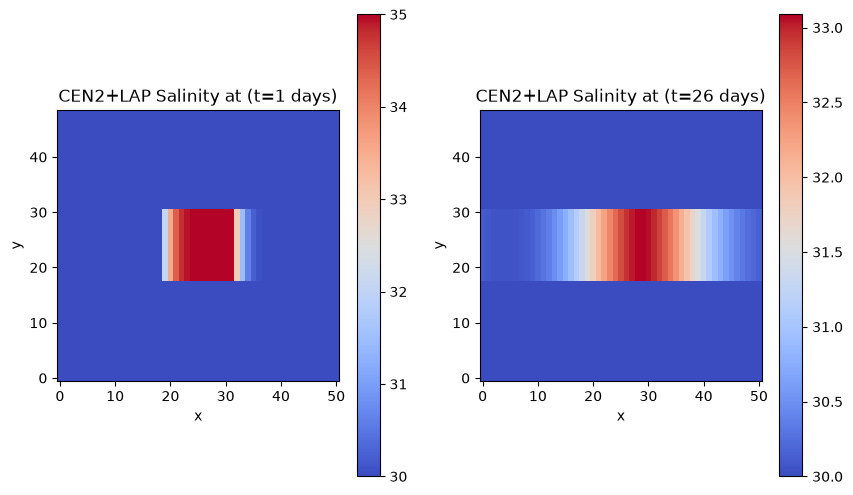

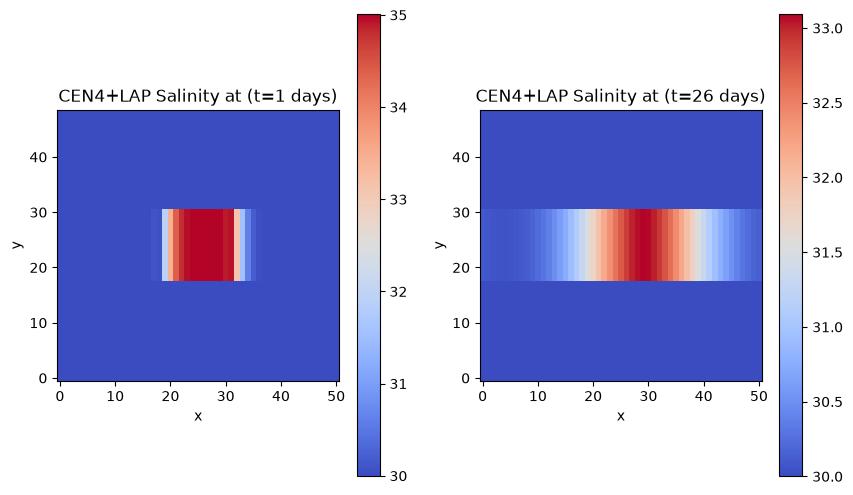

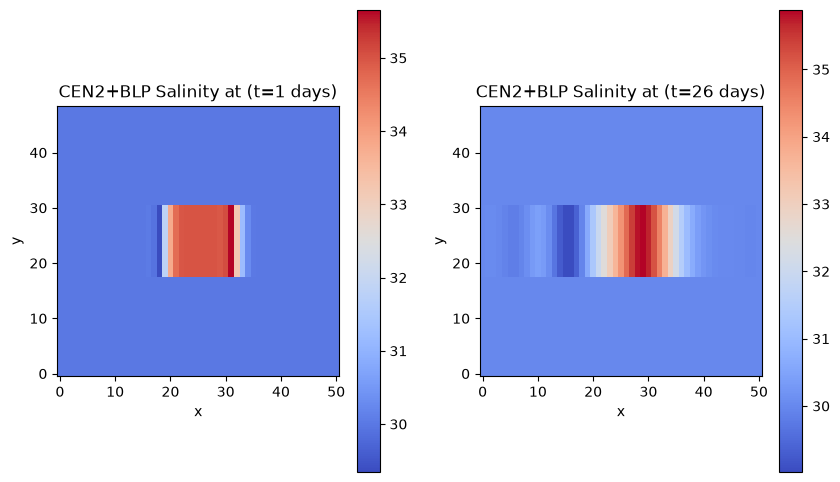

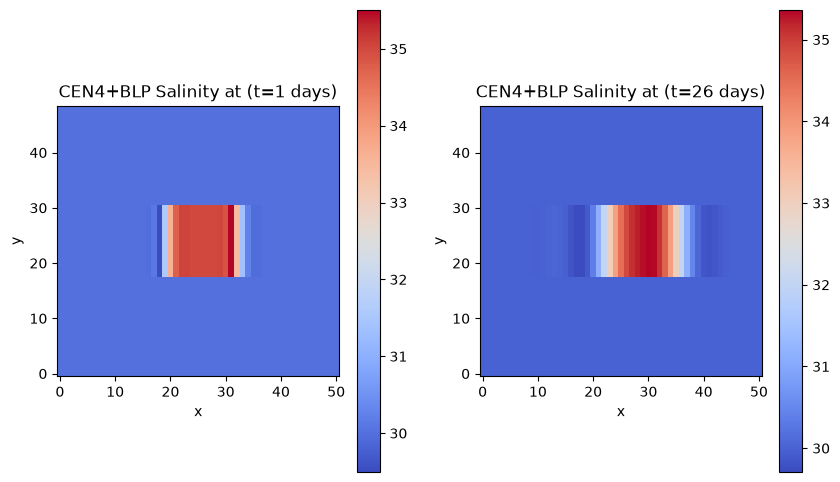

In [58]:
#show_t (t_list=[0,25], param='soce', title='CEN2 Salinity', file='CANAL_saltblock_traldfOFF_cen2_all_grid.nc' , rep=rep)
show_t (t_list=[0,25], param='soce', title='CEN2+LAP Salinity', file='CANAL_saltblock_lap_cen2_all_grid.nc' , rep=rep)
show_t (t_list=[0,25], param='soce', title='CEN4+LAP Salinity', file='CANAL_saltblock_lap_cen4_all_grid.nc' , rep=rep)
show_t (t_list=[0,25], param='soce', title='CEN2+BLP Salinity', file='CANAL_saltblock_blp_cen2_all_grid.nc' , rep=rep)
show_t (t_list=[0,25], param='soce', title='CEN4+BLP Salinity', file='CANAL_saltblock_blp_cen4_all_grid.nc' , rep=rep)


        

### Salinity along the x-axis

In [59]:
schemes = { 'cen2 + lap': cen2_lap, 'cen4 + lap' : cen4_lap, 'cen2 + blp' : cen2_blp,  'cen4 + blp': cen4_blp}
colors = {'cen2': 'red', 'cen2 + lap': 'orange', 'cen4 + lap' : 'yellow', 'cen2 + blp' : 'green',  'cen4 + blp': 'lightgreen'}

soce = {n: ds['soce'].isel(y_grid_T=25, deptht=0).values
          for n, ds in schemes.items()}

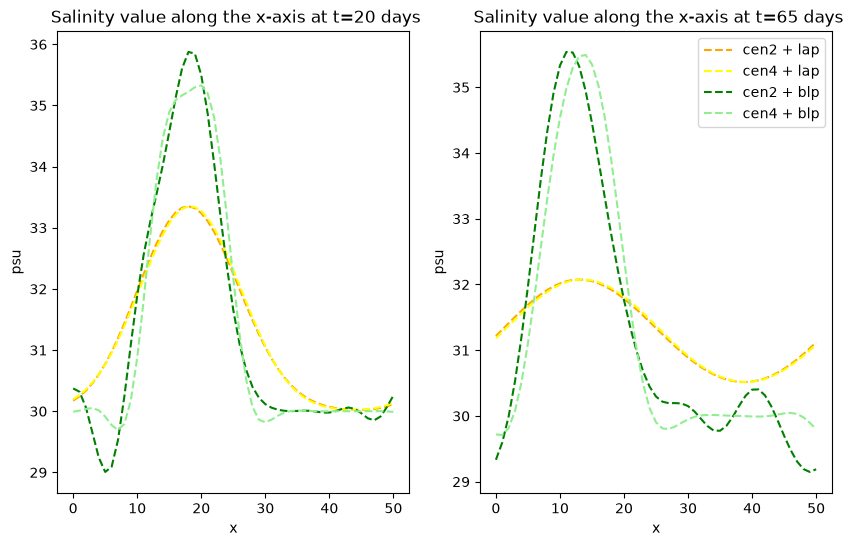

In [60]:
t_list = [20, 65]

fig, ax = plt.subplots(1, len(t_list), figsize=(10,6))

for i,t in enumerate(t_list):
    for n, ds in soce.items() :
        ax[i].plot(np.arange(ds.shape[1]), ds[t], '--', color = colors[n], label = n)
    ax[i].set_xlabel('x')
    ax[i].set_ylabel('psu')
    ax[i].set_title(f' Salinity value along the x-axis at t={t} days')

plt.legend()

### Salinity variance

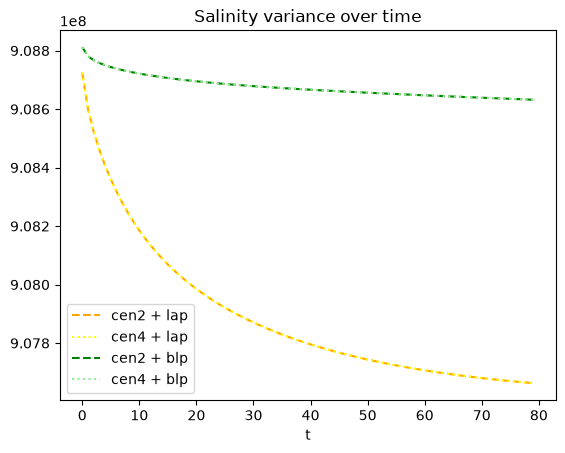

In [61]:
for n, ds in schemes.items() :
    if '4' in n:
        marker = ':'
    elif '2' in n :
        marker = '--'
    s2c = ds.salt2c.mean(dim=('x_grid_T', 'y_grid_T'))
    dep = np.arange(s2c.shape[0])
    plt.plot(dep,  s2c, marker, color =colors[n], label = n)
    

plt.title("Salinity variance over time")
plt.xlabel('t')

plt.legend()
plt.show()

For more explanations, see Annex 3-B.